<a href="https://colab.research.google.com/github/vaideheedaf/ML-Coral-reef/blob/main/Coral_Bleaching_Random_Forest_CORRECTED_EXECUTED.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Coral Bleaching Classification — Random Forest

This notebook performs a **traditional Machine Learning Random Forest classification** of coral samples into **Bleached** and **Healthy** classes using the handcrafted numerical features already present in the supplied CSV files.

**Datasets:** `ML_train.csv`, `ML_valid.csv`, `ML_test.csv`

The validation set is used only for intermediate evaluation/sanity checking. No hyperparameter tuning is performed, so the fixed Random Forest settings are not selected using validation performance. The test set is kept untouched until the final evaluation.

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    ConfusionMatrixDisplay, roc_curve
)
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
TRAIN_PATH = "ML_train.csv"
VALID_PATH = "ML_valid.csv"
TEST_PATH = "ML_test.csv"

In [4]:
# Load the three supplied datasets
train_df = pd.read_csv("/content/ML_train.csv")
valid_df = pd.read_csv("/content/ML_valid.csv")
test_df = pd.read_csv("/content/ML_test.csv")

print("Train shape:", train_df.shape)
print("Validation shape:", valid_df.shape)
print("Test shape:", test_df.shape)

print("\nTarget distribution:")
print("TRAIN\n", train_df["target"].value_counts())
print("\nVALID\n", valid_df["target"].value_counts())
print("\nTEST\n", test_df["target"].value_counts())

Train shape: (9662, 12)
Validation shape: (463, 12)
Test shape: (257, 12)

Target distribution:
TRAIN
 target
Bleached    4980
Healthy     4682
Name: count, dtype: int64

VALID
 target
Bleached    240
Healthy     223
Name: count, dtype: int64

TEST
 target
Bleached    135
Healthy     122
Name: count, dtype: int64


In [5]:
FEATURES = [
    "mean_saturation",
    "mean_brightness",
    "white_pixel_pct",
    "mean_lightness",
    "lbp_mean",
    "glcm_contrast",
    "glcm_homogeneity",
    "edge_density",
    "entropy",
]
TARGET = "target"
LABELS = ["Bleached", "Healthy"]

for name, df in {"train": train_df, "valid": valid_df, "test": test_df}.items():
    missing = [col for col in FEATURES + [TARGET] if col not in df.columns]
    if missing:
        raise ValueError(f"Missing columns in {name}: {missing}")

    unexpected = sorted(set(df[TARGET].dropna().unique()) - set(LABELS))
    if unexpected:
        raise ValueError(f"Unexpected target labels in {name}: {unexpected}")

    print(f"{name}: missing feature values = {int(df[FEATURES].isna().sum().sum())}")
    print(f"{name}: infinite feature values = {int(np.isinf(df[FEATURES].to_numpy()).sum())}")

print("\nUsing features:", FEATURES)
print("Target labels:", LABELS)

train: missing feature values = 0
train: infinite feature values = 0
valid: missing feature values = 0
valid: infinite feature values = 0
test: missing feature values = 0
test: infinite feature values = 0

Using features: ['mean_saturation', 'mean_brightness', 'white_pixel_pct', 'mean_lightness', 'lbp_mean', 'glcm_contrast', 'glcm_homogeneity', 'edge_density', 'entropy']
Target labels: ['Bleached', 'Healthy']


In [6]:
# Prepare X/y. image_id and image_path are identifiers and are NOT ML features.
X_train = train_df[FEATURES].replace([np.inf, -np.inf], np.nan).copy()
X_valid = valid_df[FEATURES].replace([np.inf, -np.inf], np.nan).copy()
X_test = test_df[FEATURES].replace([np.inf, -np.inf], np.nan).copy()

y_train = train_df[TARGET].copy()
y_valid = valid_df[TARGET].copy()
y_test = test_df[TARGET].copy()

# Median imputation is fitted on TRAIN ONLY.
imputer = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=FEATURES, index=X_train.index)
X_valid_imp = pd.DataFrame(imputer.transform(X_valid), columns=FEATURES, index=X_valid.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=FEATURES, index=X_test.index)

print("Imputation completed using training-set medians only.")

Imputation completed using training-set medians only.


In [7]:
# Train Random Forest
rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf.fit(X_train_imp, y_train)

print("Random Forest training completed successfully.")
print("Number of trees:", rf.n_estimators)
print("Training accuracy:", round(accuracy_score(y_train, rf.predict(X_train_imp)), 4))

Random Forest training completed successfully.
Number of trees: 500
Training accuracy: 1.0


In [8]:
# Validation evaluation
valid_pred = rf.predict(X_valid_imp)

print("VALIDATION RESULTS")
print("Accuracy :", round(accuracy_score(y_valid, valid_pred), 4))
print("Precision:", round(precision_score(y_valid, valid_pred, pos_label="Bleached", zero_division=0), 4))
print("Recall   :", round(recall_score(y_valid, valid_pred, pos_label="Bleached", zero_division=0), 4))
print("F1-score :", round(f1_score(y_valid, valid_pred, pos_label="Bleached", zero_division=0), 4))
print("\nClassification report:\n")
print(classification_report(y_valid, valid_pred, labels=LABELS, zero_division=0))

VALIDATION RESULTS
Accuracy : 0.9503
Precision: 0.9502
Recall   : 0.9542
F1-score : 0.9522

Classification report:

              precision    recall  f1-score   support

    Bleached       0.95      0.95      0.95       240
     Healthy       0.95      0.95      0.95       223

    accuracy                           0.95       463
   macro avg       0.95      0.95      0.95       463
weighted avg       0.95      0.95      0.95       463



Validation confusion matrix (rows = actual, columns = predicted):
[[229  11]
 [ 12 211]]


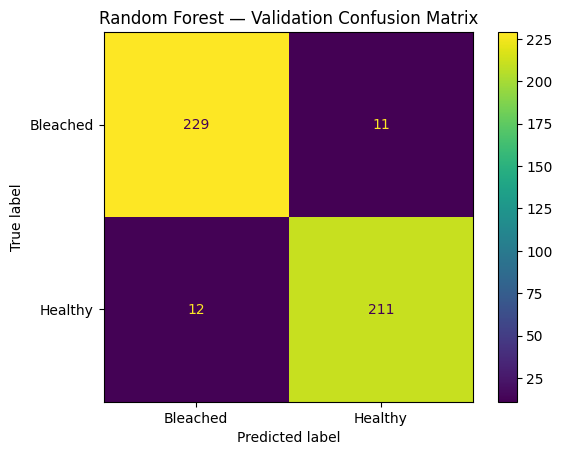

In [9]:
# Correct validation confusion matrix
cm = confusion_matrix(y_valid, valid_pred, labels=LABELS)
print("Validation confusion matrix (rows = actual, columns = predicted):")
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=LABELS)
disp.plot(values_format="d")
plt.title("Random Forest — Validation Confusion Matrix")
plt.show()

Impurity-based feature importance:


,importance
mean_saturation,0.340825
white_pixel_pct,0.187310
entropy,0.081456
mean_brightness,0.079339
mean_lightness,0.074883
lbp_mean,0.063117
glcm_homogeneity,0.062793
glcm_contrast,0.055160
edge_density,0.055115


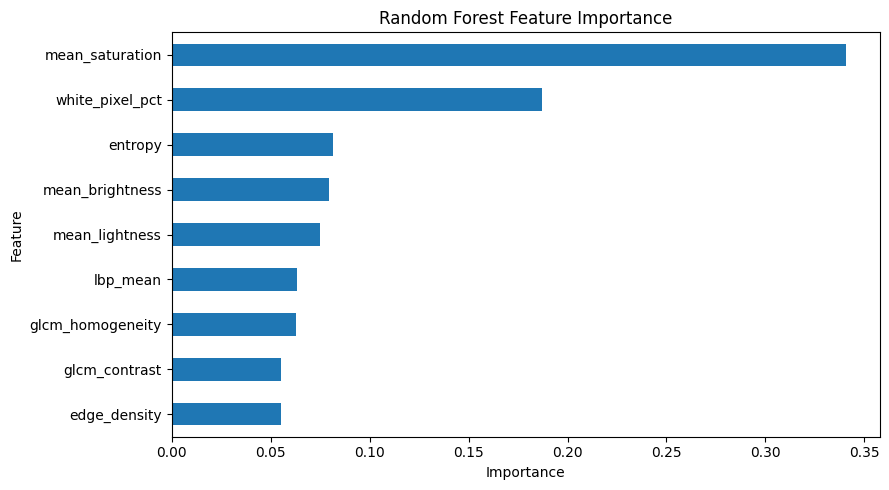

In [10]:
# Feature importance from the trained Random Forest
importance = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=False)

print("Impurity-based feature importance:")
display(importance.to_frame("importance"))

plt.figure(figsize=(9, 5))
importance.sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [11]:
# Permutation importance on the validation set
# This is a model-agnostic check of whether the features are actually useful for validation predictions.
perm = permutation_importance(
    rf, X_valid_imp, y_valid,
    n_repeats=20,
    random_state=RANDOM_STATE,
    scoring="accuracy",
    n_jobs=-1
)

perm_importance = pd.DataFrame({
    "feature": FEATURES,
    "mean_importance": perm.importances_mean,
    "std": perm.importances_std
}).sort_values("mean_importance", ascending=False)

print("Permutation importance on validation set:")
display(perm_importance)

Permutation importance on validation set:


,feature,mean_importance,std
0,mean_saturation,0.236393,0.015893
2,white_pixel_pct,0.121166,0.011116
6,glcm_homogeneity,0.048056,0.005709
3,mean_lightness,0.033045,0.006833
8,entropy,0.032937,0.006582
1,mean_brightness,0.027106,0.007434
5,glcm_contrast,0.019762,0.003880
4,lbp_mean,0.015011,0.004010
7,edge_density,0.013715,0.004334


In [12]:
# Grouped cross-validation robustness check on TRAIN only
# Roboflow-style filenames contain a source name before '.rf.<hash>'.
def source_group(path):
    name = str(path).replace("\\", "/").split("/")[-1]
    return name.split(".rf.")[0] if ".rf." in name else name

groups = train_df["image_path"].map(source_group)
print("Unique source groups in train:", groups.nunique())

cv_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features="sqrt",
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

gkf = GroupKFold(n_splits=5)
cv_scores = cross_val_score(
    cv_pipeline, train_df[FEATURES], y_train,
    cv=gkf, groups=groups, scoring="accuracy", n_jobs=-1
)

print("Grouped 5-fold CV accuracy:", np.round(cv_scores, 4))
print("Mean grouped CV accuracy:", round(cv_scores.mean(), 4))
print("Std grouped CV accuracy:", round(cv_scores.std(), 4))

Unique source groups in train: 1130
Grouped 5-fold CV accuracy: [0.9292 0.9099 0.9068 0.942  0.912 ]
Mean grouped CV accuracy: 0.92
Std grouped CV accuracy: 0.0135


In [13]:
# Final evaluation on the untouched test set
test_pred = rf.predict(X_test_imp)

print("FINAL TEST RESULTS")
print("Accuracy :", round(accuracy_score(y_test, test_pred), 4))
print("Precision:", round(precision_score(y_test, test_pred, pos_label="Bleached", zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, test_pred, pos_label="Bleached", zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, test_pred, pos_label="Bleached", zero_division=0), 4))
print("\nClassification report:\n")
print(classification_report(y_test, test_pred, labels=LABELS, zero_division=0))

FINAL TEST RESULTS
Accuracy : 0.9611
Precision: 0.9699
Recall   : 0.9556
F1-score : 0.9627

Classification report:

              precision    recall  f1-score   support

    Bleached       0.97      0.96      0.96       135
     Healthy       0.95      0.97      0.96       122

    accuracy                           0.96       257
   macro avg       0.96      0.96      0.96       257
weighted avg       0.96      0.96      0.96       257



Test confusion matrix (rows = actual, columns = predicted):
[[129   6]
 [  4 118]]


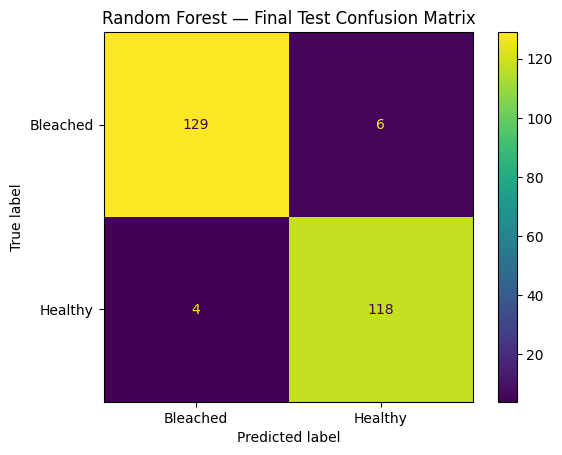

In [14]:
# Correct final test confusion matrix
cm_test = confusion_matrix(y_test, test_pred, labels=LABELS)
print("Test confusion matrix (rows = actual, columns = predicted):")
print(cm_test)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=LABELS)
disp.plot(values_format="d")
plt.title("Random Forest — Final Test Confusion Matrix")
plt.show()

Test ROC-AUC: 0.9912


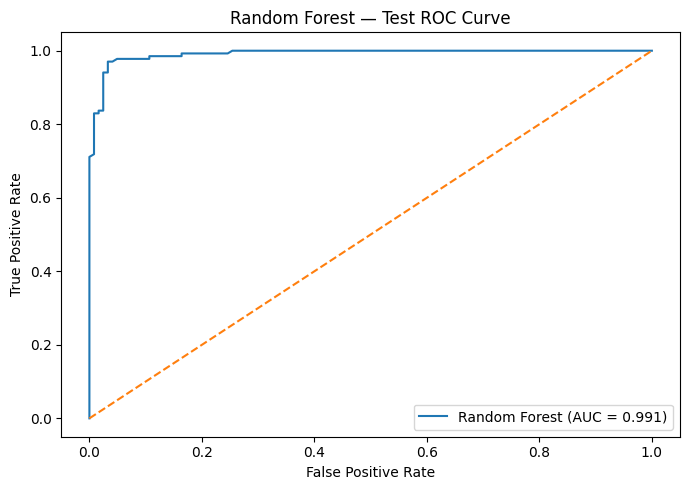

In [15]:
# ROC-AUC and ROC curve for the Bleached class
class_to_index = {cls: i for i, cls in enumerate(rf.classes_)}
if "Bleached" in class_to_index and len(rf.classes_) == 2:
    bleached_idx = class_to_index["Bleached"]
    test_prob = rf.predict_proba(X_test_imp)[:, bleached_idx]
    y_test_binary = (y_test == "Bleached").astype(int)
    auc = roc_auc_score(y_test_binary, test_prob)
    print("Test ROC-AUC:", round(auc, 4))

    fpr, tpr, _ = roc_curve(y_test_binary, test_prob)
    plt.figure(figsize=(7, 5))
    plt.plot(fpr, tpr, label=f"Random Forest (AUC = {auc:.3f})")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Random Forest — Test ROC Curve")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("ROC-AUC skipped because the target is not binary.")

In [16]:
# Approximate 95% Wilson confidence interval for test accuracy
def wilson_ci(successes, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2*n)) / denom
    half = z * np.sqrt((p*(1-p)/n) + (z**2/(4*n**2))) / denom
    return center - half, center + half

correct = int((y_test == test_pred).sum())
lo, hi = wilson_ci(correct, len(y_test))
print(f"Test accuracy: {correct}/{len(y_test)} = {correct/len(y_test):.4f}")
print(f"Approximate 95% confidence interval: {lo:.4f} to {hi:.4f}")

Test accuracy: 247/257 = 0.9611
Approximate 95% confidence interval: 0.9299 to 0.9787


In [17]:
# Save test predictions for further analysis
results = test_df[["image_id", "image_path", TARGET]].copy()
results["predicted_target"] = test_pred

if "Bleached" in class_to_index and len(rf.classes_) == 2:
    results["bleached_probability"] = test_prob

results.to_csv("random_forest_test_predictions.csv", index=False)
print("Saved: random_forest_test_predictions.csv")
display(results.head(10))

Saved: random_forest_test_predictions.csv


,image_id,image_path,target,predicted_target,bleached_probability
0,test_img1,test/Bleached/coral1_jpg.rf.f3e4be06deaef9b5f0...,Bleached,Bleached,0.644
1,test_img2,test/Bleached/coral2_jpeg_jpg.rf.f3c21b3561c7f...,Bleached,Healthy,0.080
2,test_img3,test/Bleached/coral4_jpeg_jpg.rf.d19dc42135064...,Bleached,Bleached,0.706
3,test_img4,test/Bleached/youtube-101_jpg.rf.7493baada8f2f...,Bleached,Bleached,0.826
4,test_img5,test/Bleached/youtube-103_jpg.rf.4496e45d25087...,Bleached,Bleached,0.950
5,test_img6,test/Bleached/youtube-109_jpg.rf.bad4131e6fb74...,Bleached,Bleached,0.860
6,test_img7,test/Bleached/youtube-1100_jpg.rf.f3b62ed02a48...,Bleached,Bleached,0.980
7,test_img8,test/Bleached/youtube-116_jpg.rf.715e07964a11b...,Bleached,Bleached,0.852
8,test_img9,test/Bleached/youtube-1191_jpg.rf.4ba8e1440932...,Bleached,Bleached,0.934
9,test_img10,test/Bleached/youtube-1194_jpg.rf.fe13b6054b31...,Bleached,Bleached,0.930


## Conclusion

The Random Forest model classifies the supplied coral samples as **Bleached** or **Healthy** using the nine handcrafted features available in the CSV files. `image_id` and `image_path` are identifiers and are not used as predictors.

The validation set is used only for an intermediate sanity check; no hyperparameter tuning is performed. The test set is reserved for final evaluation. The confusion matrices use the correct class names: **Bleached** and **Healthy**.

Grouped cross-validation is included as a robustness check because augmented images may share the same original source image. Any future hyperparameter tuning or cross-validation should use source-image groups to reduce optimistic estimates. Permutation importance is also included to support the impurity-based Random Forest feature importance.